<div dir="rtl">

# تمرین اول مبانی بینایی کامپیوتر

</div>

<div dir="rtl">

## بخش اول: تحلیل و جداسازی رنگ‌ها در تصاویر دیجیتال

</div>

<div dir="rtl">

### ۱. بررسی مشخصات تصویر

</div>

<div dir="rtl">

تصویر با OpenCV بارگذاری می‌شود. ترتیب کانال‌های تصویر رنگی در خروجی `cv2.imread` برابر BGR (آبی، سبز، قرمز) است. محدودهٔ گزارش‌شده، کمترین و بیشترین مقدار واقعی میان همهٔ پیکسل‌ها و کانال‌هاست.

</div>

In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

image_path = Path("Media_src/Peppers.png")
image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

In [ ]:
height, width, channels = image.shape

print(f"Image dimensions (height x width): {height} x {width} pixels")
print(f"Array shape (height, width, channels): {image.shape}")
print(f"Data type: {image.dtype}")
print(f"Number of color channels: {channels}")
print("Channel order: BGR (Blue, Green, Red)")
print(f"Pixel value range: {image.min()} to {image.max()}")

<div dir="rtl">

برای نمایش درست رنگ‌ها با Matplotlib، تصویر BGR به RGB تبدیل می‌شود. این تبدیل فقط برای نمایش است و مشخصات بالا از تصویر بارگذاری‌شده محاسبه شده‌اند.

</div>

In [ ]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
# plt.imshow(image)
plt.title("Peppers")
plt.axis("off")
plt.show()

<div dir="rtl">

### ۲. تبدیل انواع تصاویر

تصویر خاکستری با تبدیل استاندارد OpenCV ساخته می‌شود. برای تصویر 
دودویی، آستانهٔ ثابت ۱۲۷ انتخاب شده است؛ مقادیر بزرگ‌تر از آن سفید و بقیه سیاه می‌شوند.

 در تبدیل به خاکستری اطلاعات رنگ و در تبدیل به دودویی، علاوه بر رنگ، جزئیات سطوح روشنایی نیز از دست می‌روند.

</div>

In [ ]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
threshold = 127
_, binary = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, picture, title in zip(axes, [image_rgb, gray, binary], ["RGB", "Grayscale", "Binary (threshold = 127)"]):
    ax.imshow(picture, cmap="gray" if picture.ndim == 2 else None, vmin=0, vmax=255)
    # ax.imshow(picture, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۳. بررسی فضاهای رنگی RGB و HSV

در RGB هر کانال سهم یک رنگ اصلی را نشان می‌دهد. در HSV، مؤلفه‌های رنگ‌فام (H)، اشباع (S) و روشنایی (V) جدا شده‌اند؛ بنابراین با وجود حساسیت به نور و اشباع کم، HSV برای تعیین بازهٔ رنگی اجسام مناسب‌تر است. در OpenCV برای تصویر ۸ بیتی، H در بازهٔ ۰ تا ۱۷۹ و دو کانال دیگر در بازهٔ ۰ تا ۲۵۵ قرار دارند.

</div>

In [ ]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (color_image, names) in enumerate([(image_rgb, ["Red", "Green", "Blue"]), (hsv, ["Hue", "Saturation", "Value"])]):
    for index, name in enumerate(names):
        axes[row, index].imshow(color_image[:, :, index], cmap="gray", vmin=0, vmax=179 if name == "Hue" else 255)
        axes[row, index].set_title(name)
        axes[row, index].axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۴. جداسازی نواحی سبز

برای شناسایی رنگ سبز از بازهٔ HSV با حدود `[35, 50, 40]` تا `[85, 255, 255]` استفاده می‌شود. حداقل اشباع و روشنایی برای کاهش انتخاب نواحی خاکستری و بسیار تاریک است. این روش فقط بر اساس رنگ تصمیم می‌گیرد؛ بنابراین ممکن است برگ، ساقه یا پس‌زمینهٔ سبز نیز انتخاب شوند و تضمین نمی‌کند همهٔ پیکسل‌های ماسک متعلق به فلفل باشند.

در خروجی این تصویر علاوه بر بدنهٔ فلفل‌های سبز، ساقه‌های سبز فلفل‌های قرمز، زرد و نارنجی نیز انتخاب شده‌اند. همچنین بخش‌هایی از فلفل‌های سبز در نواحی تیره یا بازتاب نور از ماسک جا مانده‌اند.

</div>

In [ ]:
import numpy as np

# [Hue, Saturation, Value]
green_lower = np.array([35, 50, 40], dtype=np.uint8)
green_upper = np.array([85, 255, 255], dtype=np.uint8)

# green_lower = np.array([35, 5, 0], dtype=np.uint8)
# green_upper = np.array([85, 255, 255], dtype=np.uint8)

def extract_green(bgr_image):
    hsv_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv_image, green_lower, green_upper)
    result = cv2.bitwise_and(bgr_image, bgr_image, mask=mask)
    return mask, result

green_mask, green_image = extract_green(image)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, picture, title in zip(axes, [image_rgb, green_mask, cv2.cvtColor(green_image, cv2.COLOR_BGR2RGB)], ["Original", "Green mask", "Extracted green"]):
    ax.imshow(picture, cmap="gray" if picture.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Green mask coverage: {np.mean(green_mask > 0) * 100:.2f}%")

<div dir="rtl">

### ۵. هیستوگرام و کنتراست

کنتراست RMS، انحراف معیار شدت پیکسل‌های تصویر خاکستری است. در اینجا شدت‌ها بر ۲۵۵ تقسیم می‌شوند، پس مقدار کنتراست بدون واحد و در مقیاس صفر تا یک است. برای تغییر کنتراست، فاصلهٔ هر پیکسل از میانگین تصویر در یک ضریب ضرب و مقادیر به بازهٔ مجاز محدود می‌شوند. ضریب ۱٫۵ کنتراست را افزایش و ضریب ۰٫۵ آن را کاهش می‌دهد؛ برش در دو انتهای بازه می‌تواند بخشی از جزئیات را از بین ببرد.

</div>

In [ ]:
def rms_contrast(gray_image):
    return np.std(gray_image.astype(np.float64) / 255.0)

def change_contrast(gray_image, factor):
    mean = gray_image.mean()
    adjusted = (gray_image.astype(np.float64) - mean) * factor + mean
    return np.clip(adjusted, 0, 255).astype(np.uint8)

contrast_images = [gray, change_contrast(gray, 1.5), change_contrast(gray, 0.5)]
contrast_names = ["Original", "Higher contrast", "Lower contrast"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for index, (picture, name) in enumerate(zip(contrast_images, contrast_names)):
    axes[0, index].imshow(picture, cmap="gray", vmin=0, vmax=255)
    axes[0, index].set_title(f"{name} (RMS = {rms_contrast(picture):.4f})")
    axes[0, index].axis("off")
    axes[1, index].hist(picture.ravel(), bins=256, range=(0, 256))
    axes[1, index].set_xlim(0, 255)
    axes[1, index].set_xlabel("Intensity")
    axes[1, index].set_ylabel("Pixel count")
plt.tight_layout()
plt.show()
for name, picture in zip(contrast_names, contrast_images):
    print(f"{name}: RMS = {rms_contrast(picture):.4f}")
print(f"Original grayscale: min = {gray.min()}, max = {gray.max()}, mean = {gray.mean():.2f}")

<div dir="rtl">

هیستوگرام بالا توزیع واقعی روشنایی تصویر را نشان می‌دهد. در نسخهٔ پرکنتراست، مقادیر از میانگین دورتر می‌شوند و ممکن است در صفر و ۲۵۵ انباشته شوند؛ در نسخهٔ کم‌کنتراست توزیع به میانگین نزدیک‌تر می‌شود. مقادیر عددی چاپ‌شده میزان تغییر را مشخص می‌کنند.

در تصویر خاکستری اصلی، سهم بازه‌های ۰–۶۳، ۶۴–۱۲۷، ۱۲۸–۱۹۱ و ۱۹۲–۲۵۵ به‌ترتیب 13.9، 25.6، 51.4 و 9.1 درصد است. میانگین شدت حدود ۱۳۰ است.

</div>

<div dir="rtl">

### ۶. بهبود تصویر در نور نامناسب

برای شبیه‌سازی نور ضعیف، کانال روشنایی V در فضای HSV در ۰٫۳ ضرب می‌شود. برای حفظ تقریبی رنگ‌فام و اشباع، همسان‌سازی هیستوگرام و کشش خطی تنها روی کانال V تصویر تاریک اعمال می‌شوند و سپس تصویر به BGR برمی‌گردد. کشش، کمینه و بیشینهٔ موجود در کانال V را به ۰ و ۲۵۵ می‌نگارد. همسان‌سازی به توزیع مقادیر وابسته است، اما کشش، فاصله‌های نسبی شدت را به‌صورت خطی حفظ می‌کند؛ تبدیل و گرد کردن می‌توانند باعث تغییر جزئی رنگ شوند.

</div>

In [ ]:
dark_hsv = hsv.copy()
dark_hsv[:, :, 2] = (hsv[:, :, 2].astype(np.float32) * 0.3).astype(np.uint8)
dark_image = cv2.cvtColor(dark_hsv, cv2.COLOR_HSV2BGR)

# Start from the same dark image for both enhancement methods.
dark_hsv = cv2.cvtColor(dark_image, cv2.COLOR_BGR2HSV)
dark_value = dark_hsv[:, :, 2]

equalized_hsv = dark_hsv.copy()
equalized_hsv[:, :, 2] = cv2.equalizeHist(dark_value)
equalized_image = cv2.cvtColor(equalized_hsv, cv2.COLOR_HSV2BGR)

stretched_hsv = dark_hsv.copy()
value_min, value_max = int(dark_value.min()), int(dark_value.max())
if value_max > value_min:
    stretched = (dark_value.astype(np.float32) - value_min) * 255 / (value_max - value_min)
    stretched_hsv[:, :, 2] = np.clip(stretched, 0, 255).astype(np.uint8)
stretched_image = cv2.cvtColor(stretched_hsv, cv2.COLOR_HSV2BGR)

enhanced_images = [dark_image, equalized_image, stretched_image]
enhanced_names = ["Dark", "Histogram equalization", "Histogram stretching"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for index, (picture, name) in enumerate(zip(enhanced_images, enhanced_names)):
    axes[0, index].imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
    axes[0, index].set_title(name)
    axes[0, index].axis("off")
    value = cv2.cvtColor(picture, cv2.COLOR_BGR2HSV)[:, :, 2]
    axes[1, index].hist(value.ravel(), bins=256, range=(0, 256))
    axes[1, index].set_xlim(0, 255)
    axes[1, index].set_xlabel("Value (V)")
    axes[1, index].set_ylabel("Pixel count")
    print(f"{name}: V range = {value.min()} to {value.max()}, mean = {value.mean():.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

در نمودارها هیستوگرام کانال V، همان کانال پردازش‌شده، نمایش داده شده است. همسان‌سازی می‌تواند توزیع روشنایی را به شکل غیرخطی تغییر دهد و جزئیات بعضی بازه‌ها را تقویت کند؛ کشش با تبدیل خطی دامنه را گسترش می‌دهد و به کمینه و بیشینه حساس است. هیچ‌یک تضمین نمی‌کند روشنایی اصلی دقیقاً بازیابی شود.

</div>

<div dir="rtl">

### ۷. تأثیر بهبود تصویر بر جداسازی رنگ

همان تابع و حدود HSV قسمت ۴، بدون تغییر، برای تصویر اصلی، تاریک و دو تصویر بهبودیافته استفاده می‌شوند. نسبت پیکسل‌های انتخاب‌شده و اشتراک بر اجتماع (IoU) هر ماسک با ماسک اصلی گزارش می‌شوند. ماسک اصلی مرجع مقایسه است، نه دادهٔ حقیقت مبنا؛ در نتیجه IoU میزان شباهت به خروجی اولیه را نشان می‌دهد و معیار دقت واقعی تشخیص فلفل نیست.

</div>

In [ ]:
comparison_images = [image, dark_image, equalized_image, stretched_image]
comparison_names = ["Original", "Dark", "Equalized", "Stretched"]
comparison_masks = [extract_green(picture)[0] for picture in comparison_images]
reference = green_mask > 0

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, mask, name in zip(axes, comparison_masks, comparison_names):
    selected = mask > 0
    union = np.logical_or(reference, selected).sum()
    iou = np.logical_and(reference, selected).sum() / union if union else 1.0
    coverage = selected.mean() * 100
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}\nCoverage: {coverage:.2f}% | IoU: {iou:.3f}")
    ax.axis("off")
    print(f"{name}: coverage = {coverage:.2f}%, IoU with original = {iou:.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

تاریک‌سازی می‌تواند پیکسل‌ها را به زیر حداقل روشنایی تعیین‌شده ببرد و از ماسک حذف کند. بهبود روشنایی ممکن است بخشی از آن‌ها را بازگرداند یا پیکسل‌های تازه‌ای را وارد ماسک کند. مقایسهٔ درصد پوشش و IoU در خروجی بالا نشان می‌دهد هر روش برای این تصویر چقدر ماسک را نسبت به حالت اصلی تغییر داده است؛ شباهت بیشتر به ماسک اصلی لزوماً به معنی تشخیص درست‌تر فلفل نیست.

برای این تصویر، پوشش ماسک از ۱۱٫۵۹٪ در حالت اصلی به ۱٫۹۸٪ در حالت تاریک می‌رسد. پس از همسان‌سازی و کشش به‌ترتیب ۵٫۰۲٪ و ۱۱٫۸۲٪ است. IoU این سه حالت با ماسک اصلی به‌ترتیب ۰٫۱۶۴، ۰٫۴۲۱ و ۰٫۹۸۱ است؛ در این آزمایش کشش بیشترین شباهت را به ماسک اولیه دارد.

</div>

<div dir="rtl">

## بخش دوم: پردازش و بازیابی تصویر سند اسکن‌شده

</div>

<div dir="rtl">

### ۱. بارگذاری تصویر و اضافه کردن نویز

تصویر سند برای پردازش شدت و تحلیل خوانایی به خاکستری تبدیل می‌شود. نویز فلفل‌نمکی با چگالی ۵٪، پیکسل‌های انتخاب‌شده را با احتمال برابر صفر یا ۲۵۵ می‌کند. نویز گاوسی با میانگین صفر و انحراف معیار ۲۵ به شدت همهٔ پیکسل‌ها اضافه می‌شود و نتیجه به بازهٔ مجاز بریده می‌شود. نویز فلفل‌نمکی ضربه‌ای و پراکنده است، اما نویز گاوسی به‌صورت پیوسته در سراسر تصویر تغییر ایجاد می‌کند. بذر تصادفی ثابت برای تکرارپذیری استفاده شده است.

</div>

In [ ]:
document_path = Path("Media_src/scanned_document.png")
document_color = cv2.imread(str(document_path), cv2.IMREAD_COLOR)
if document_color is None:
    raise FileNotFoundError(f"Could not load image: {document_path}")
document = cv2.cvtColor(document_color, cv2.COLOR_BGR2GRAY)
print(f"Original image shape: {document_color.shape}, dtype: {document_color.dtype}, channel order: BGR")
print(f"Grayscale shape: {document.shape}, dtype: {document.dtype}, range: {document.min()} to {document.max()}")

rng = np.random.default_rng(42)
noise_density = 0.05
random_values = rng.random(document.shape)
salt_pepper = document.copy()
salt_pepper[random_values < noise_density / 2] = 0
salt_pepper[(random_values >= noise_density / 2) & (random_values < noise_density)] = 255
gaussian_sigma = 25
gaussian_noise = rng.normal(0, gaussian_sigma, document.shape)
gaussian_noisy = np.clip(document.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, picture, name in zip(axes, [document, salt_pepper, gaussian_noisy], ["Original", "Salt and pepper (5%)", "Gaussian (sigma = 25)"]):
    ax.imshow(picture, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۲. کرنل و پیاده‌سازی فیلترگذاری مکانی

کرنل ماتریسی کوچک از ضرایب است که با پیمایش تصویر، مقادیر همسایگی هر پیکسل را ترکیب می‌کند؛ از آن برای محوشدن، حذف نویز و استخراج لبه استفاده می‌شود. در کانولوشن، کرنل ابتدا در هر دو جهت برگردانده می‌شود، سپس حاصل‌ضرب عضو به عضو آن با همسایگی جمع می‌شود. تابع زیر این عملیات را مستقیماً با جمع وزن‌دار برش‌های تصویر انجام می‌دهد و هر کرنل دوبعدی با ابعاد فرد را می‌پذیرد. برای مرزها از انعکاس بدون تکرار پیکسل مرزی (`reflect`) استفاده شده است. خروجی اعشاری و علامت‌دار باقی می‌ماند تا پاسخ فیلترهای لبه از بین نرود.

</div>

In [ ]:
def spatial_convolution(gray_image, kernel):
    kernel = np.asarray(kernel, dtype=np.float32)
    if gray_image.ndim != 2 or kernel.ndim != 2 or any(size % 2 == 0 for size in kernel.shape):
        raise ValueError("The image must be grayscale and the kernel must have odd dimensions.")
    pad_y, pad_x = kernel.shape[0] // 2, kernel.shape[1] // 2
    padded = np.pad(gray_image.astype(np.float32), ((pad_y, pad_y), (pad_x, pad_x)), mode="reflect")
    result = np.zeros(gray_image.shape, dtype=np.float32)
    flipped_kernel = kernel[::-1, ::-1]
    height, width = gray_image.shape
    for row in range(kernel.shape[0]):
        for col in range(kernel.shape[1]):
            result += flipped_kernel[row, col] * padded[row:row + height, col:col + width]
    return result

def to_uint8(values):
    return np.clip(np.rint(values), 0, 255).astype(np.uint8)

<div dir="rtl">

### ۳. فیلترهای پایین‌گذر

فیلتر پایین‌گذر تغییرات سریع شدت را تضعیف می‌کند و برای کاهش نویز به کار می‌رود، اما می‌تواند لبه‌ها و جزئیات حروف را نیز محو کند. فیلتر میانگین از وزن‌های یکسان و فیلتر گاوسی از وزن‌های بیشتر در مرکز استفاده می‌کند. کرنل گاوسی ۵×۵ در اینجا حاصل ضرب بردار `[1, 4, 6, 4, 1]` در خودش و تقسیم بر ۲۵۶ است. میانه یک فیلتر غیرخطی است: مقادیر پنجره را مرتب کرده و مقدار میانی را برمی‌گزیند؛ در مرزها، مانند `medianBlur`، پیکسل مرزی تکرار می‌شود.

</div>

In [ ]:
mean_kernel = np.ones((3, 3), dtype=np.float32) / 9
gaussian_weights = np.array([1, 4, 6, 4, 1], dtype=np.float32)
gaussian_kernel = np.outer(gaussian_weights, gaussian_weights) / 256

def median_filter(gray_image, window_size=3):
    if gray_image.ndim != 2 or window_size < 1 or window_size % 2 == 0:
        raise ValueError("The image must be grayscale and the window size must be positive and odd.")
    radius = window_size // 2
    padded = np.pad(gray_image, radius, mode="edge")
    height, width = gray_image.shape
    neighbors = np.stack([padded[row:row + height, col:col + width]
                          for row in range(window_size) for col in range(window_size)])
    return np.partition(neighbors, window_size * window_size // 2, axis=0)[window_size * window_size // 2]

noisy_images = {"Salt and pepper": salt_pepper, "Gaussian": gaussian_noisy}
manual_results = {}
for noise_name, noisy_image in noisy_images.items():
    manual_results[noise_name] = {
        "Mean": to_uint8(spatial_convolution(noisy_image, mean_kernel)),
        "Gaussian": to_uint8(spatial_convolution(noisy_image, gaussian_kernel)),
        "Median": median_filter(noisy_image, 3),
    }

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for row, (noise_name, noisy_image) in enumerate(noisy_images.items()):
    pictures = [noisy_image] + list(manual_results[noise_name].values())
    for ax, picture, title in zip(axes[row], pictures, [noise_name, "Mean 3x3", "Gaussian 5x5", "Median 3x3"]):
        ax.imshow(picture, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

فیلتر میانه معمولاً برای نویز فلفل‌نمکی مناسب‌تر است، زیرا نقاط پرت را با مقدار میانی همسایگی جایگزین می‌کند، بدون آنکه مقدار پرت را در میانگین پخش کند. در نویز گاوسی، میانگین و گاوسی با ترکیب نمونه‌های همسایه تغییرات تصادفی را کاهش می‌دهند، ولی ممکن است لبه‌ها را محو کنند. میانه هم می‌تواند خطوط باریک و جزئیات کوچک را حذف کند؛ کاهش نویز الزاماً به معنای حفظ بهتر جزئیات نیست.

</div>

<div dir="rtl">

### ۴. فیلترهای بالاگذر و استخراج لبه

فیلتر بالاگذر تغییرات سریع شدت را برجسته می‌کند و در تشخیص لبه کاربرد دارد. Sobel مشتق جهت‌دار را در دو راستا تخمین می‌زند و اندازهٔ گرادیان از آن‌ها محاسبه می‌شود. Laplacian تغییر مشتق را بررسی می‌کند و به تغییر شدت در جهت‌های مختلف پاسخ می‌دهد. برای نمایش، قدر مطلق پاسخ Laplacian و اندازهٔ گرادیان Sobel در بازهٔ ۰ تا ۲۵۵ بریده می‌شوند؛ محاسبات اصلی قبل از نمایش اعشاری و علامت‌دار هستند.

</div>

In [ ]:
sobel_x_kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
sobel_y_kernel = sobel_x_kernel.T
laplacian_kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)

def manual_edges(gray_image):
    gx = spatial_convolution(gray_image, sobel_x_kernel)
    gy = spatial_convolution(gray_image, sobel_y_kernel)
    laplacian = spatial_convolution(gray_image, laplacian_kernel)
    return gx, gy, laplacian

edge_inputs = {"Original": document, "Salt and pepper": salt_pepper,
               "Median restored": manual_results["Salt and pepper"]["Median"]}
manual_edge_results = {name: manual_edges(picture) for name, picture in edge_inputs.items()}
fig, axes = plt.subplots(3, 3, figsize=(12, 13))
for row, (name, picture) in enumerate(edge_inputs.items()):
    gx, gy, laplacian = manual_edge_results[name]
    displays = [picture, to_uint8(np.hypot(gx, gy)), to_uint8(np.abs(laplacian))]
    for ax, result, title in zip(axes[row], displays, [name, "Sobel magnitude", "Laplacian absolute"]):
        ax.imshow(result, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

نقاط نویز تغییر شدت شدید ایجاد می‌کنند و در خروجی Sobel و به‌ویژه Laplacian به صورت پاسخ‌های اضافی دیده می‌شوند. اعمال میانه پیش از استخراج لبه بسیاری از نقاط ضربه‌ای را حذف می‌کند، اما ممکن است هم‌زمان لبه‌های ظریف یا جزئیات کوچک حروف را تغییر دهد.

</div>

<div dir="rtl">

### ۵. مقایسه با OpenCV و ارزیابی PSNR

برای مقایسهٔ منصفانه، در فیلترهای خطی حالت مرزی `BORDER_REFLECT_101` و در میانه تکرار پیکسل مرزی استفاده می‌شود. OpenCV برای میانگین و گاوسی خروجی ۸ بیتی با گرد کردن تولید می‌کند. Sobel در OpenCV همبستگی اعمال می‌کند؛ چون تابع دستی کانولوشن واقعی است، علامت خروجی Sobel آماده پیش از مقایسه معکوس می‌شود. کرنل Laplacian متقارن است. اختلاف‌ها روی خروجی‌های خام محاسبه می‌شوند، نه تصاویر بریده‌شده برای نمایش. PSNR بر اساس بیشینهٔ ۲۵۵ و خطای میانگین مربعات نسبت به سند اصلی محاسبه می‌شود؛ مقدار بالاتر نشان‌دهندهٔ خطای پیکسلی کمتر است.

</div>

In [ ]:
opencv_results = {}
for noise_name, noisy_image in noisy_images.items():
    opencv_results[noise_name] = {
        "Mean": cv2.blur(noisy_image, (3, 3), borderType=cv2.BORDER_REFLECT_101),
        "Gaussian": cv2.GaussianBlur(noisy_image, (5, 5), 0, borderType=cv2.BORDER_REFLECT_101),
        "Median": cv2.medianBlur(noisy_image, 3),
    }

def psnr(reference, result):
    difference = reference.astype(np.float64) - result.astype(np.float64)
    mse = np.mean(difference ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print(f"{'Noise':<17} {'Filter':<10} {'Manual PSNR':>12} {'OpenCV PSNR':>12} {'Max diff':>9} {'Mean diff':>10}")
for noise_name in noisy_images:
    for filter_name in manual_results[noise_name]:
        manual = manual_results[noise_name][filter_name]
        ready = opencv_results[noise_name][filter_name]
        difference = np.abs(manual.astype(np.int16) - ready.astype(np.int16))
        print(f"{noise_name:<17} {filter_name:<10} {psnr(document, manual):>10.2f} dB {psnr(document, ready):>10.2f} dB {difference.max():>9} {difference.mean():>10.4f}")
    print(f"{noise_name} noisy input PSNR: {psnr(document, noisy_images[noise_name]):.2f} dB")

print("\nMaximum absolute difference between raw manual and OpenCV edge responses:")
for name, picture in edge_inputs.items():
    gx, gy, laplacian = manual_edge_results[name]
    cv_gx = -cv2.Sobel(picture, cv2.CV_32F, 1, 0, ksize=3, borderType=cv2.BORDER_REFLECT_101)
    cv_gy = -cv2.Sobel(picture, cv2.CV_32F, 0, 1, ksize=3, borderType=cv2.BORDER_REFLECT_101)
    cv_laplacian = cv2.Laplacian(picture, cv2.CV_32F, ksize=1, borderType=cv2.BORDER_REFLECT_101)
    print(f"{name}: Sobel X = {np.max(np.abs(gx - cv_gx)):.0f}, Sobel Y = {np.max(np.abs(gy - cv_gy)):.0f}, Laplacian = {np.max(np.abs(laplacian - cv_laplacian)):.0f}")

<div dir="rtl">

جدول بالا کیفیت نسخه‌های بازیابی‌شده و اختلاف پیاده‌سازی دستی با OpenCV را نشان می‌دهد. اختلاف‌های کوچک احتمالی در فیلترهای پایین‌گذر ناشی از شیوهٔ محاسبه و گرد کردن است. PSNR برای ارزیابی پیکسلی مفید است، اما به‌تنهایی خوانایی حروف یا حفظ مرزها را تضمین نمی‌کند؛ تصویر خروجی و جزئیات حروف نیز باید بررسی شوند.

</div>

<div dir="rtl">

برای بررسی بهتر خوانایی، برشی یکسان از حروف سند اصلی، تصاویر نویزدار و خروجی هر سه فیلتر نمایش داده می‌شود.

</div>

In [ ]:
crop = np.s_[930:1230, 150:900]
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
for row, (noise_name, noisy_image) in enumerate(noisy_images.items()):
    pictures = [document, noisy_image] + list(manual_results[noise_name].values())
    for ax, picture, title in zip(axes[row], pictures, ["Original", noise_name, "Mean", "Gaussian", "Median"]):
        ax.imshow(picture[crop], cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

در این آزمایش، فیلتر میانه برای هر دو نویز بیشترین PSNR را داشته است: برای نویز فلفل‌نمکی ۳۶٫۳۹ دسی‌بل و برای نویز گاوسی ۲۸٫۵۳ دسی‌بل. در حالت گاوسی، پس از آن فیلتر گاوسی با ۲۶٫۶۴ و میانگین با ۲۶٫۳۸ دسی‌بل قرار دارند. این نتیجه به همین سند، شدت نویز و اندازهٔ پنجره مربوط است و برتری همیشگی میانه برای نویز گاوسی را ثابت نمی‌کند. تصویر سند عمدتاً نواحی یکنواخت و مرزهای تیز دارد، بنابراین حفظ مرزها می‌تواند در نتیجه مؤثر باشد.

خروجی دستی میانگین و میانه با OpenCV در این اجرا یکسان بود. اختلاف فیلتر گاوسی حداکثر یک سطح شدت بود؛ اختلاف PSNR آن در نویز فلفل‌نمکی حدود ۰٫۰۲ دسی‌بل است که به نحوهٔ گرد کردن و محاسبات عددی مربوط می‌شود. پاسخ‌های خام Sobel و Laplacian در هر سه ورودی پس از تطبیق علامت، یکسان بودند. حتی فیلتر دارای PSNR بالاتر نیز ممکن است اجزای باریک حروف را حذف کند؛ بنابراین برش بالا را نیز باید در کنار جدول بررسی کرد.

</div>

<div dir="rtl">

## بخش سوم: پردازش و بازیابی ویدئو

### ۱. بارگذاری و بررسی مشخصات ویدئو

مشخصات ویدئوی ورودی با OpenCV خوانده می‌شوند. مدت تقریبی با تقسیم تعداد فریم بر نرخ فریم محاسبه می‌شود.

</div>

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = Path("Media_src/park_video.mp4")
capture = cv2.VideoCapture(str(video_path))
if not capture.isOpened():
    raise FileNotFoundError(f"Could not open video: {video_path}")
frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
fps = capture.get(cv2.CAP_PROP_FPS)
width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
capture.release()
if frame_count <= 0 or fps <= 0 or width <= 0 or height <= 0:
    raise ValueError("Video properties are invalid.")
print(f"Frame count: {frame_count}")
print(f"FPS: {fps:.2f}")
print(f"Frame dimensions (width x height): {width} x {height}")
print(f"Duration: {frame_count / fps:.2f} seconds")

Frame count: 450
FPS: 30.00
Frame dimensions (width x height): 1280 x 720
Duration: 15.00 seconds


<div dir="rtl">

### ۲. افزودن نویز فلفل‌نمکی

در هر فریم دقیقاً ۵٪ از موقعیت‌های پیکسل، بدون تکرار، به‌صورت تصادفی انتخاب می‌شوند؛ نیمی به سفید و نیمی به سیاه تبدیل می‌شوند. هر سه کانال یک پیکسل با هم تغییر می‌کنند. بذر تصادفی ثابت، آزمایش را تکرارپذیر می‌کند. ویدئو با کدک `mp4v` ذخیره می‌شود؛ چون فشرده‌سازی اتلافی است، پیکسل‌های فایل ذخیره‌شده لزوماً دقیقاً صفر یا ۲۵۵ باقی نمی‌مانند.

</div>

In [2]:
output_dir = Path("Media_out")
output_dir.mkdir(exist_ok=True)
noisy_path = output_dir / "noisy_video.mp4"
median_path = output_dir / "filtered_video_1.mp4"
gaussian_path = output_dir / "filtered_video_2.mp4"
video_codec = cv2.VideoWriter_fourcc(*"mp4v")

def open_video_writer(path):
    writer = cv2.VideoWriter(str(path), video_codec, fps, (width, height))
    if not writer.isOpened():
        raise RuntimeError(f"Could not create video: {path}")
    return writer

rng_video = np.random.default_rng(42)
noisy_capture = cv2.VideoCapture(str(video_path))
noisy_writer = open_video_writer(noisy_path)
processed_frames = 0
noise_pixels = int(round(height * width * 0.05))
try:
    while True:
        success, frame = noisy_capture.read()
        if not success:
            break
        noisy_frame = frame.copy()
        positions = rng_video.choice(height * width, size=noise_pixels, replace=False)
        pixels = noisy_frame.reshape(-1, 3)
        pixels[positions[:noise_pixels // 2]] = 0
        pixels[positions[noise_pixels // 2:]] = 255
        noisy_writer.write(noisy_frame)
        processed_frames += 1
finally:
    noisy_capture.release()
    noisy_writer.release()
if processed_frames != frame_count:
    raise RuntimeError(f"Read {processed_frames} frames but metadata says {frame_count}.")
print(f"Noisy video saved: {noisy_path} ({processed_frames} frames)")
print(f"Changed positions per frame: {noise_pixels} ({noise_pixels / (height * width) * 100:.2f}%)")

Noisy video saved: Media_out/noisy_video.mp4 (450 frames)
Changed positions per frame: 46080 (5.00%)


<div dir="rtl">

برای مقایسهٔ تصویری، اولین فریم از ویدئوهای ذخیره‌شده خوانده می‌شود.

</div>

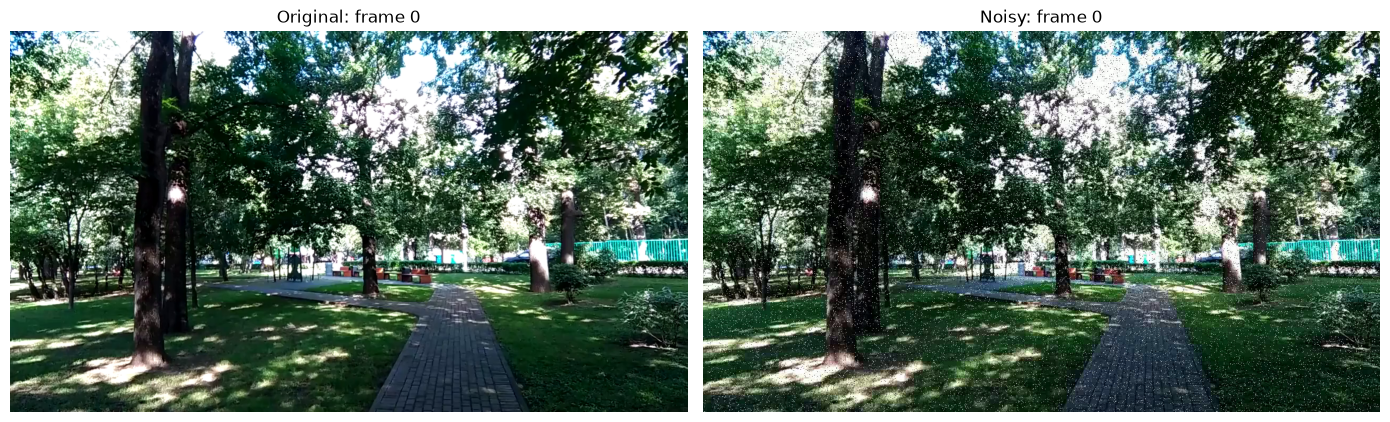

In [3]:
def read_frame(path, index):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {path}")
    try:
        capture.set(cv2.CAP_PROP_POS_FRAMES, index)
        success, frame = capture.read()
        if not success:
            raise RuntimeError(f"Could not read frame {index} from {path}")
        return frame
    finally:
        capture.release()

first_original = read_frame(video_path, 0)
first_noisy = read_frame(noisy_path, 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, frame, name in zip(axes, [first_original, first_noisy], ["Original: frame 0", "Noisy: frame 0"]):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۳ و ۴. حذف نویز و مقایسهٔ دو فیلتر

فیلتر اول میانه با پنجرهٔ ۳×۳ است؛ این فیلتر غیرخطی معمولاً نقاط پرت فلفل‌نمکی را بدون میانگین‌گیری از آن‌ها حذف می‌کند. فیلتر دوم گاوسی با کرنل ۵×۵ و `sigma=0` است؛ این فیلتر خطی با میانگین‌گیری وزنی نویز را هموار می‌کند، اما ممکن است نقاط نویز را پخش و لبه‌ها را محو کند. هر دو فیلتر به‌طور مستقل روی همان فریم‌های خوانده‌شده از فایل نویزدار اعمال می‌شوند، نه به ترتیب روی خروجی یکدیگر.

</div>

In [4]:
filter_capture = cv2.VideoCapture(str(noisy_path))
if not filter_capture.isOpened():
    raise RuntimeError(f"Could not open noisy video: {noisy_path}")
median_writer = open_video_writer(median_path)
try:
    gaussian_writer = open_video_writer(gaussian_path)
except Exception:
    median_writer.release()
    filter_capture.release()
    raise
filtered_frames = 0
try:
    while True:
        success, noisy_frame = filter_capture.read()
        if not success:
            break
        median_frame = cv2.medianBlur(noisy_frame, 3)
        gaussian_frame = cv2.GaussianBlur(noisy_frame, (5, 5), 0)
        median_writer.write(median_frame)
        gaussian_writer.write(gaussian_frame)
        filtered_frames += 1
finally:
    filter_capture.release()
    median_writer.release()
    gaussian_writer.release()
if filtered_frames != processed_frames:
    raise RuntimeError(f"Filtered {filtered_frames} of {processed_frames} noisy frames.")
print(f"Median output: {median_path}, {filtered_frames} frames")
print(f"Gaussian output: {gaussian_path}, {filtered_frames} frames")

Median output: Media_out/filtered_video_1.mp4, 450 frames
Gaussian output: Media_out/filtered_video_2.mp4, 450 frames


<div dir="rtl">

### ۵. بررسی و تحلیل نتایج

فریم‌های ابتدا، میانه و انتهای ویدئو در چهار حالت مقایسه می‌شوند. برای تکمیل مقایسهٔ بصری، PSNR هر فریم بازیابی‌شده نسبت به همان فریم اصلی گزارش می‌شود. مقدار بیشتر به معنی خطای پیکسلی کمتر است و به‌تنهایی حفظ جزئیات یا کیفیت ادراکی را تضمین نمی‌کند. مقایسه بعد از ذخیره‌سازی و خواندن مجدد فایل‌ها انجام می‌شود و شامل اثر فشرده‌سازی ویدئو نیز هست.

</div>

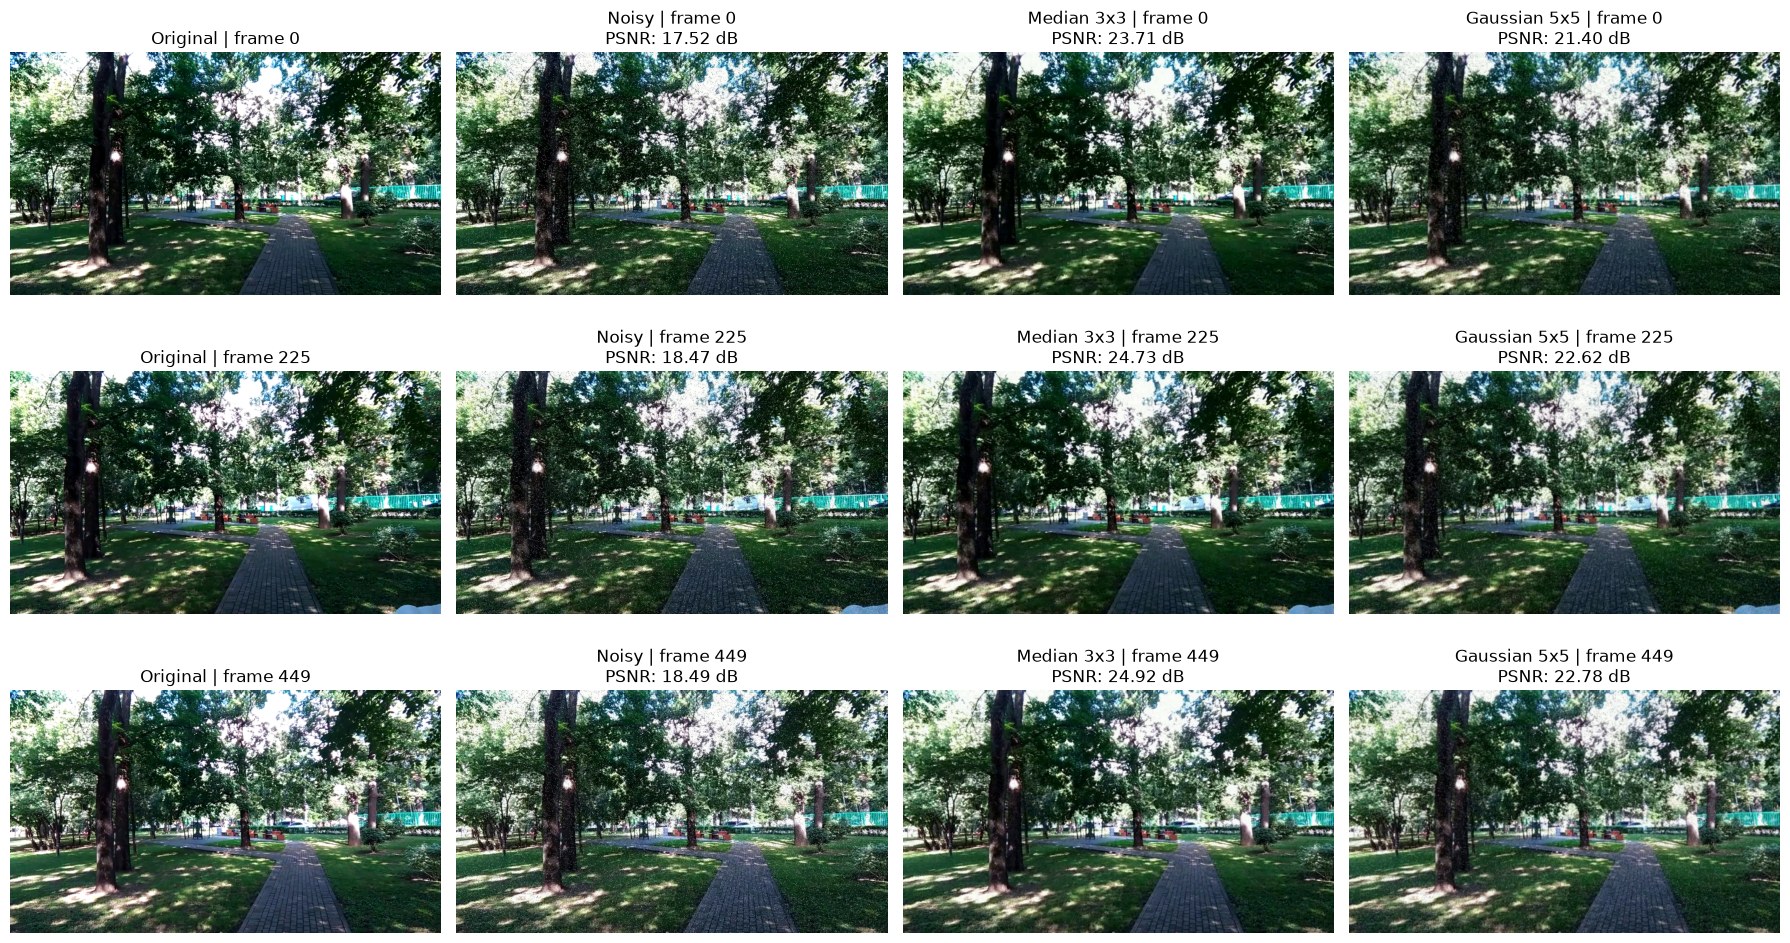

Mean PSNR over the three selected frames:
Noisy: 18.16 dB
Median 3x3: 24.45 dB
Gaussian 5x5: 22.26 dB


In [5]:
def frame_psnr(reference, result):
    difference = reference.astype(np.float32) - result.astype(np.float32)
    mse = np.mean(difference ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

video_paths = [video_path, noisy_path, median_path, gaussian_path]
video_names = ["Original", "Noisy", "Median 3x3", "Gaussian 5x5"]
sample_indices = [0, frame_count // 2, frame_count - 1]
sample_scores = {name: [] for name in video_names[1:]}
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for row, index in enumerate(sample_indices):
    frames = [read_frame(path, index) for path in video_paths]
    for col, (ax, frame, name) in enumerate(zip(axes[row], frames, video_names)):
        title = f"{name} | frame {index}"
        if col > 0:
            score = frame_psnr(frames[0], frame)
            sample_scores[name].append(score)
            title += f"\nPSNR: {score:.2f} dB"
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()
print("Mean PSNR over the three selected frames:")
for name, scores in sample_scores.items():
    print(f"{name}: {np.mean(scores):.2f} dB")

<div dir="rtl">

برای ارزیابی حفظ ویژگی‌های ویدئو، تعداد فریم، نرخ فریم و ابعاد همهٔ فایل‌های ذخیره‌شده دوباره خوانده و با ورودی مقایسه می‌شوند.

</div>

In [6]:
print(f"{'Video':<16} {'Frames':>8} {'FPS':>8} {'Width':>8} {'Height':>8} {'Matches input':>15}")
for path, name in zip(video_paths, video_names):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {path}")
    count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    rate = capture.get(cv2.CAP_PROP_FPS)
    frame_width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    capture.release()
    matches = count == frame_count and abs(rate - fps) < 0.01 and (frame_width, frame_height) == (width, height)
    print(f"{name:<16} {count:>8} {rate:>8.2f} {frame_width:>8} {frame_height:>8} {str(matches):>15}")

Video              Frames      FPS    Width   Height   Matches input
Original              450    30.00     1280      720            True
Noisy                 450    30.00     1280      720            True
Median 3x3            450    30.00     1280      720            True
Gaussian 5x5          450    30.00     1280      720            True


<div dir="rtl">

فیلتر میانه برای نویز ضربه‌ای مناسب است و معمولاً لبه‌ها را بهتر از هموارسازی گاوسی حفظ می‌کند، اما بافت و اجسام کوچک ممکن است تغییر کنند. فیلتر گاوسی با ترکیب پیکسل‌های همسایه، نواحی نویزدار و همچنین لبه‌ها و جزئیات محیط را نرم می‌کند. هر دو روش مستقل روی هر فریم اعمال شده‌اند و از اطلاعات زمانی استفاده نمی‌کنند؛ بنابراین با حرکت اجسام، امکان تغییر ظاهری جزئیات بین فریم‌ها وجود دارد. اعداد و فریم‌های بالا مبنای مقایسهٔ این آزمایش‌اند.

</div>

<div dir="rtl">

در فریم‌های ۰، ۲۲۵ و ۴۴۹، میانگین PSNR تصویر نویزدار ۱۸٫۱۶، خروجی میانه ۲۴٫۴۵ و خروجی گاوسی ۲۲٫۲۶ دسی‌بل است؛ بنابراین در این سه نمونه، میانه هم از نظر این معیار و هم در کاهش نقاط برجستهٔ نویز عملکرد بهتری دارد. در نمای پارک، بافت ریز برگ‌ها و مرز مسیر در هر دو خروجی نسبت به تصویر اصلی نرم‌ترند و هموارسازی گاوسی تارشدگی بیشتری ایجاد می‌کند. جزئیات کوچک و اجسام دور یا متحرک نیز ممکن است در نتیجهٔ فیلتر و فشرده‌سازی تغییر کنند؛ این سه فریم به‌تنهایی برای ارزیابی پیوستگی حرکت کافی نیستند.

هر سه فایل خروجی، مانند فایل اصلی، ۴۵۰ فریم با نرخ ۳۰ فریم بر ثانیه و ابعاد ۱۲۸۰×۷۲۰ دارند. نتیجهٔ PSNR فقط بر اساس این سه فریم نمونه است، نه تمام ویدئو.

</div>